# PRAKTIKUM PERTEMUAN 11 — GAUSSIAN NAIVE BAYES DAN SVM
## 150 menit | Pembuktian manual → implementasi scikit-learn → data Iris nyata → evaluasi adil

**Mata kuliah:** DAIS32W — Pembelajaran Mesin · Semester 3  
**Nama:** Bartolomeus Simanjuntak  **NIM:** 255314091  **Kelas:** Pembelajaran Mesin EP

**Kompetensi setelah praktikum:**
1. Memverifikasi **prior, mean, varians, likelihood Gaussian, posterior** untuk dua batch Iris, lalu memeriksa hasil dengan `GaussianNB`.
2. Menghubungkan **margin dan hinge loss** SVM dengan **update SGD satu dan dua fitur**, serta membuktikan prediksi manual.
3. Melatih `GaussianNB` dan `SVC` pada **Iris asli**, memakai training / validation / test terpisah tanpa leakage.
4. Menjelaskan fungsi parameter `priors`, `var_smoothing`, `kernel`, `C`, `gamma`, `degree`, dan `coef0` **berdasarkan eksperimen**.
5. Membandingkan kedua algoritma menggunakan **Macro-F1, confusion matrix, serta kesalahan per kelas**, bukan intuisi saja.

  
**Perangkat:** Python 3, Jupyter Notebook/JupyterLab/Google Colab, `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `IPython`. Dataset `load_iris()` sudah tersedia dalam scikit-learn.  
**Instruksi:. Isi jawaban **di notebook ini**, simpan output perhitungan dan gambar, serta **jangan memakai hasil test untuk memilih model**.

> **Dua eksperimen berbeda.** (A) Demonstrasi manual hanya memakai beberapa ID Iris dan bukan skor generalisasi. (B) Percobaan algoritma memakai split formal 90/30/30. Delapan ID demonstrasi diletakkan di **training** sejak awal agar tidak mencemari validation/test. Total Iris tetap 150 observasi.

## P11.1 — Setup dan pembagian data tanpa leakage

**Konsep penting:** `load_iris(as_frame=True)` mengambil 150 observasi dengan empat pengukuran numerik. `train_test_split` mempunyai parameter:

| Parameter | Fungsi |
|---|---|
| `train_size` / `test_size` | Menentukan jumlah atau proporsi baris yang dipisahkan |
| `random_state` | Menetapkan urutan acak agar eksperimen dapat direproduksi |
| `stratify` | Menjaga komposisi kelas pada pemisahan sedekat mungkin |

ID demonstrasi manual telah ditetapkan berdasarkan modul: `50,51,52,53,100,101,102,123`. **Tidak satu pun masuk validation/test**. Sisa data dibagi stratified menjadi 82 train tambahan, 30 validation, dan 30 test. Dengan delapan ID latihan, train berjumlah 90. Test tetap disimpan tetapi baru dievaluasi pada P11.8.

In [1]:
import sys, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, recall_score, confusion_matrix,
                             classification_report)

SEED=2026
np.set_printoptions(suppress=True, precision=6)
plt.rcParams.update({'figure.figsize':(6.8,4.0),'font.size':10})
print('Python:',sys.version.split()[0],'| scikit-learn:',sklearn.__version__)
iris=load_iris(as_frame=True)
raw=iris.data.rename(columns={
 'sepal length (cm)':'sepal_length','sepal width (cm)':'sepal_width',
 'petal length (cm)':'petal_length','petal width (cm)':'petal_width'}).copy()
raw['kelas_id']=np.asarray(iris.target,dtype=int)
raw['kelas']=[str(iris.target_names[int(i)]) for i in iris.target]
raw.index.name='iris_id'
PETAL=['petal_length','petal_width']
DEMO_IDS=[50,51,52,53,100,101,102,123]
remaining_ids=raw.index[~raw.index.isin(DEMO_IDS)]
extra_train_ids,hold_ids=train_test_split(
 remaining_ids,train_size=82,test_size=60,random_state=SEED,
 stratify=raw.loc[remaining_ids,'kelas_id'])
val_ids,test_ids=train_test_split(hold_ids,train_size=30,test_size=30,
 random_state=SEED+1,stratify=raw.loc[hold_ids,'kelas_id'])
train_ids=np.concatenate([np.array(DEMO_IDS),np.array(extra_train_ids)])
X_all=raw[['sepal_length','sepal_width']+PETAL]
y_all=raw['kelas_id']
X_train=X_all.loc[train_ids].copy(); y_train=y_all.loc[train_ids].copy()
X_val=X_all.loc[val_ids].copy(); y_val=y_all.loc[val_ids].copy()
X_test=X_all.loc[test_ids].copy(); y_test=y_all.loc[test_ids].copy()  # disimpan hingga P11.8
X_tr=X_train[PETAL].copy(); X_va=X_val[PETAL].copy()
assert (len(X_train),len(X_val),len(X_test))==(90,30,30)
assert len(set(train_ids)&set(val_ids))==len(set(train_ids)&set(test_ids))==0
assert set(DEMO_IDS).issubset(set(train_ids))
print('Data keseluruhan:',raw.shape, '| split:',len(train_ids),len(val_ids),len(test_ids))
print('Target:',dict(enumerate(iris.target_names)))
display(raw.head(4))
print('Kelas TRAIN:',y_train.value_counts().sort_index().to_dict())

Python: 3.14.7 | scikit-learn: 1.9.1
Data keseluruhan: (150, 6) | split: 90 30 30
Target: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


,sepal_length,sepal_width,petal_length,petal_width,kelas_id,kelas
iris_id,,,,,,
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa


Kelas TRAIN: {0: 29, 1: 31, 2: 30}


**PERTANYAAN P11.1-1** — Jelaskan mengapa data Iris merupakan supervised classification dan mengapa 8 ID demonstrasi dimasukkan ke training, bukan ke validation/test.

**✍ JAWABAN MAHASISWA P11.1-1**

Iris termasuk **supervised classification** karena setiap baris punya label kelas yang sudah diketahui (`kelas_id`: 0 = setosa, 1 = versicolor, 2 = virginica). Model belajar dari pasangan fitur–label (empat ukuran numerik dalam cm) lalu menebak label yang **diskret**, jadi tugasnya klasifikasi, bukan regresi atau clustering.

Kedelapan ID demonstrasi (50, 51, 52, 53, 100, 101, 102, 123) sudah kita lihat dan hitung secara manual di P11.2 dan P11.4. Kalau ada yang ikut masuk ke validation/test, kita sudah "mengenal" data itu duluan, sehingga skor evaluasinya tidak lagi mewakili data yang benar-benar baru (**leakage**). Karena itu kedelapannya ditaruh di training, lalu 142 baris sisanya dibagi stratified: 82 + 8 = **90 train**, **30 validation**, **30 test** (total 150). Hasil assert juga memastikan irisan train–val dan train–test kosong. Komposisi kelas train: setosa 29, versicolor 31, virginica 30.

## P11.2 — Verifikasi GaussianNB manual, dua batch

Sesuai Bab 3 Modul 11, kita mempelajari **Versicolor (V)** dan **Virginica (G)** menggunakan **dua fitur asli** tanpa shifting:

- **Batch 1:** Iris 50 dan 51 (V), 100 dan 101 (G) → **4 baris**.
- **Batch 2:** Iris 52 (V), 102 (G) → **2 baris baru**, sehingga kumulatif **6 baris**.
- **Titik yang diprediksi:** Iris **ID 53** = (4,0; 1,3), dan **ID 123** = (4,9; 1,8). Nilai kelas aslinya tidak dipakai menghitung prediksi.

Untuk setiap kelas k dan fitur j, hitung:

$$P(C_k)=n_k/N, \quad \mu_{jk}=\frac{1}{n_k}\sum_{i:y_i=k}x_{ij}, \quad
\sigma^2_{jk}=\frac{1}{n_k}\sum_{i:y_i=k}(x_{ij}-\mu_{jk})^2.$$

**Perhatian:** penyebut varians adalah **n**, bukan n−1 (`ddof=0`). Contoh manual menggunakan **smoothing aditif** $\sigma^2_{efektif}=\sigma^2+\delta$, dengan $\delta=0{,}05$; ini **bukan nilai parameter** `var_smoothing=0.05` di scikit-learn.

Bukti Gaussian untuk sebuah fitur:

$$p(x_j\mid C_k)=\frac{1}{\sqrt{2\pi\sigma^2_{efektif,jk}}}
\exp\!\left[-\frac{(x_j-\mu_{jk})^2}{2\sigma^2_{efektif,jk}}\right].$$

Skor kelas $S_k=P(C_k)\prod_j p(x_j\mid C_k)$. Posterior $P(C_k\mid x)=S_k/\sum_r S_r$. Gaussian menghasilkan **densitas**, yang boleh melebihi 1; jangan menyamakan densitas dengan probabilitas kelas.

In [2]:
NB_BATCH1=[50,51,100,101]
NB_BATCH2=[52,102]
NB_SIX=NB_BATCH1+NB_BATCH2
NB_QUERY=[53,123]
DELTA=.05
print('Data latihan GaussianNB manual:')
display(raw.loc[NB_SIX,PETAL+['kelas']])
print('Data uji manual (fitur saja; kelas disembunyikan):')
display(raw.loc[NB_QUERY,PETAL])

def manual_stats(ids):
    frame=raw.loc[ids,PETAL+['kelas']]
    rows=[]; params={}
    for klass in ['versicolor','virginica']:
        dat=frame.loc[frame['kelas']==klass,PETAL].to_numpy(dtype=float)
        cnt=len(dat); prior=cnt/len(frame)
        mean=dat.mean(axis=0); var=dat.var(axis=0,ddof=0)
        params[klass]={'n':cnt,'prior':prior,'mean':mean,'var':var}
        rows.append({'kelas':klass,'n':cnt,'prior':prior,
          'mean_length':mean[0],'mean_width':mean[1],
          'var_length':var[0],'var_width':var[1]})
    return pd.DataFrame(rows).set_index('kelas'),params

tab_nb1,params_nb1=manual_stats(NB_BATCH1)
tab_nb2,params_nb2=manual_stats(NB_SIX)
print('Batch 1 (N=4):');display(tab_nb1.round(6))
print('Batch 2 kumulatif (N=6):');display(tab_nb2.round(6))
assert np.allclose(params_nb1['versicolor']['mean'],[4.6,1.45])
assert np.allclose(params_nb1['versicolor']['var'],[.01,.0025])
assert np.allclose(params_nb2['virginica']['mean'],[5.6666666666667,2.1666666666667])

Data latihan GaussianNB manual:


,petal_length,petal_width,kelas
iris_id,,,
50,4.7,1.4,versicolor
51,4.5,1.5,versicolor
100,6.0,2.5,virginica
101,5.1,1.9,virginica
52,4.9,1.5,versicolor
102,5.9,2.1,virginica


Data uji manual (fitur saja; kelas disembunyikan):


,petal_length,petal_width
iris_id,,
53,4.0,1.3
123,4.9,1.8


Batch 1 (N=4):


,n,prior,mean_length,mean_width,var_length,var_width
kelas,,,,,,
versicolor,2,0.5,4.60,1.45,0.0100,0.0025
virginica,2,0.5,5.55,2.20,0.2025,0.0900


Batch 2 kumulatif (N=6):


,n,prior,mean_length,mean_width,var_length,var_width
kelas,,,,,,
versicolor,3,0.5,4.700000,1.466667,0.026667,0.002222
virginica,3,0.5,5.666667,2.166667,0.162222,0.062222


**PERTANYAAN P11.2-1** — Hitung sendiri prior, mean, dan varians populasi untuk **kedua kelas** setelah Batch 1 dan Batch 2. Mengapa prior tetap 0,5 walaupun jumlah observasi berubah?

**✍ JAWABAN MAHASISWA P11.2-1**

Rumus: $P(C_k)=n_k/N$, $\mu=\frac1n\sum x$, $\sigma^2=\frac1n\sum(x-\mu)^2$ (ddof = 0).

**Batch 1 (N = 4)**
- Versicolor (ID 50, 51): length 4,7; 4,5 → μ = 9,2/2 = **4,60**; σ² = (0,1² + 0,1²)/2 = **0,0100**. Width 1,4; 1,5 → μ = **1,45**; σ² = (0,05² + 0,05²)/2 = **0,0025**. Prior = 2/4 = **0,5**.
- Virginica (ID 100, 101): length 6,0; 5,1 → μ = **5,55**; σ² = (0,45² + 0,45²)/2 = **0,2025**. Width 2,5; 1,9 → μ = **2,20**; σ² = (0,3² + 0,3²)/2 = **0,0900**. Prior = 2/4 = **0,5**.

**Batch 2 kumulatif (N = 6)**
- Versicolor (50, 51, 52): length 4,7; 4,5; 4,9 → μ = 14,1/3 = **4,7000**; σ² = (0² + 0,2² + 0,2²)/3 = 0,08/3 = **0,026667**. Width 1,4; 1,5; 1,5 → μ = 4,4/3 = **1,466667**; σ² = (0,0667² + 0,0333² + 0,0333²)/3 = 0,006667/3 = **0,002222**. Prior = 3/6 = **0,5**.
- Virginica (100, 101, 102): length 6,0; 5,1; 5,9 → μ = 17/3 = **5,666667**; σ² = (0,3333² + 0,5667² + 0,2333²)/3 = 0,486667/3 = **0,162222**. Width 2,5; 1,9; 2,1 → μ = 6,5/3 = **2,166667**; σ² = (0,3333² + 0,2667² + 0,0667²)/3 = 0,186667/3 = **0,062222**. Prior = 3/6 = **0,5**.

Semua angka ini cocok dengan tabel output. Prior tetap 0,5 karena tiap batch menambah jumlah bunga yang **sama** untuk kedua kelas (2:2 lalu 3:3). Prior hanya bergantung pada *perbandingan* jumlah kelas, bukan jumlah totalnya.

### Langkah perhitungan posterior dengan kode Python dasar

Kode di bawah **tidak memakai GaussianNB scikit-learn**. Kode hanya menghitung rumus manual menggunakan `numpy` agar setiap langkah dapat diperiksa. `log(score)` dipakai untuk stabilitas; hasilnya sama dengan normalisasi perkalian densitas selama tidak terjadi masalah pembulatan numerik.

Rincian Batch 2 / ID 53 / δ=0,05:


,kelas,prior,likelihood_length,likelihood_width,skor_tanpa_normalisasi,posterior
0,versicolor,0.5,0.058986,1.338069,0.039464,0.999339
1,virginica,0.5,0.001245,0.041926,0.000026,0.000661


Perbandingan posterior manual:


,training,iris_id,delta,P_V,P_G,prediksi
0,Batch 1,53,0.050,0.99648,0.00352,versicolor
1,Batch 1,53,0.005,0.29637,0.70363,virginica
2,Batch 1,123,0.050,0.66826,0.33174,versicolor
3,Batch 1,123,0.005,0.00120,0.99880,virginica
4,Batch 2 kumulatif,53,0.050,0.99934,0.00066,versicolor
5,Batch 2 kumulatif,53,0.005,0.99793,0.00207,versicolor
6,Batch 2 kumulatif,123,0.050,0.82501,0.17499,versicolor
7,Batch 2 kumulatif,123,0.005,0.02611,0.97389,virginica


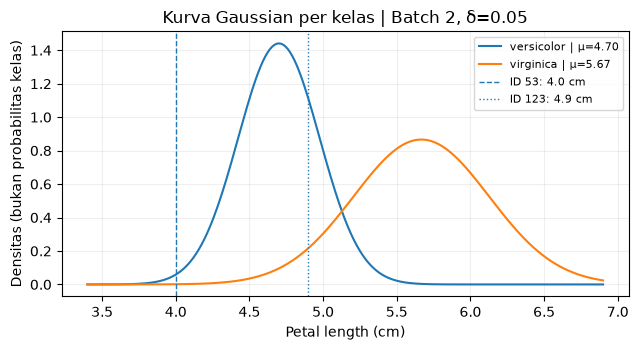

In [3]:
def gaussian_density(x_value,mean,var_eff):
    return 1/np.sqrt(2*np.pi*var_eff)*np.exp(-(x_value-mean)**2/(2*var_eff))

def gaussian_manual_predict(query,parameters,delta):
    rows=[];score=[]
    for klass,p in parameters.items():
        variance_eff=p['var']+delta
        densities=gaussian_density(np.asarray(query),p['mean'],variance_eff)
        unnormalized=p['prior']*np.prod(densities)
        rows.append({'kelas':klass,'prior':p['prior'],
           'likelihood_length':densities[0],'likelihood_width':densities[1],
           'skor_tanpa_normalisasi':unnormalized})
        score.append(unnormalized)
    prob=np.array(score)/np.sum(score)
    result=pd.DataFrame(rows)
    result['posterior']=prob
    return result

posterior_rows=[]
for ids_name,parameters in [('Batch 1',params_nb1),('Batch 2 kumulatif',params_nb2)]:
    for qid in NB_QUERY:
        vals=raw.loc[qid,PETAL].to_numpy(dtype=float)
        for delta in [.05,.005]:
            t=gaussian_manual_predict(vals,parameters,delta)
            pred=t.loc[t['posterior'].idxmax(),'kelas']
            pV=t.loc[t['kelas']=='versicolor','posterior'].iloc[0]
            pG=t.loc[t['kelas']=='virginica','posterior'].iloc[0]
            posterior_rows.append({'training':ids_name,'iris_id':qid,'delta':delta,
                'P_V':pV,'P_G':pG,'prediksi':pred})
            if ids_name=='Batch 2 kumulatif' and qid==53 and delta==.05:
                print('Rincian Batch 2 / ID 53 / δ=0,05:')
                display(t.round(7))
posterior_manual=pd.DataFrame(posterior_rows)
print('Perbandingan posterior manual:')
display(posterior_manual.round(5))
# Visualisasi likelihood Gaussian per kelas untuk satu fitur; gunakan statistik Batch 2.
fig,ax=plt.subplots(figsize=(6.5,3.6))
x_plot=np.linspace(3.4,6.9,230)
for k in ['versicolor','virginica']:
    r=params_nb2[k]
    ax.plot(x_plot,gaussian_density(x_plot,r['mean'][0],r['var'][0]+DELTA),label=f'{k} | μ={r["mean"][0]:.2f}')
ax.axvline(4.0,linestyle='--',linewidth=1,label='ID 53: 4.0 cm')
ax.axvline(4.9,linestyle=':',linewidth=1,label='ID 123: 4.9 cm')
ax.set(xlabel='Petal length (cm)',ylabel='Densitas (bukan probabilitas kelas)',
       title='Kurva Gaussian per kelas | Batch 2, δ=0.05')
ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()
assert posterior_manual.query("training=='Batch 2 kumulatif' and iris_id==53 and delta==0.05").iloc[0].prediksi=='versicolor'
assert posterior_manual.query("training=='Batch 2 kumulatif' and iris_id==123 and delta==0.005").iloc[0].prediksi=='virginica'

**PERTANYAAN P11.2-2** — Dengan statistik **Batch 2** dan δ=0,05, tulis satu substitusi rumus likelihood untuk ID 53, hitung posterior V dan G, kemudian tentukan prediksi. Apa arti nilai posterior yang sangat tinggi dari enam sampel?

**✍ JAWABAN MAHASISWA P11.2-2**

Statistik Batch 2 versicolor + δ: σ²_ef,length = 0,026667 + 0,05 = 0,076667; σ²_ef,width = 0,002222 + 0,05 = 0,052222.

**Substitusi likelihood petal length ID 53 (x = 4,0) untuk Versicolor:**
$$p(4{,}0\mid V)=\frac{1}{\sqrt{2\pi(0{,}076667)}}\exp\!\left[-\frac{(4{,}0-4{,}7)^2}{2(0{,}076667)}\right]=1{,}4408\times e^{-3{,}1957}=1{,}4408\times0{,}04093\approx\mathbf{0{,}05899}$$

Dengan cara yang sama (output kode):
| Kelas | Prior | p(length) | p(width) | Skor S = prior × p × p |
|---|---|---|---|---|
| Versicolor | 0,5 | 0,058986 | 1,338069 | 0,5 × 0,058986 × 1,338069 = **0,039464** |
| Virginica | 0,5 | 0,001245 | 0,041926 | 0,5 × 0,001245 × 0,041926 = **0,000026** |

Posterior: P(V|x) = 0,039464 / (0,039464 + 0,000026) = **0,99934**; P(G|x) = **0,00066**. **Prediksi: Versicolor.** (Catatan: p(width|V) = 1,338 > 1 tidak masalah karena itu densitas, bukan probabilitas.)

Posterior 99,9% artinya, *menurut model yang hanya dibangun dari enam bunga*, ID 53 jauh lebih cocok dengan Versicolor. Tapi angka ini bukan tingkat keyakinan yang bisa dipercaya penuh: mean dan varians dari 3 sampel per kelas sangat tidak stabil, dan nilainya ikut ditentukan oleh δ yang kita pilih sendiri. Jadi posterior tinggi ≠ akurasi tinggi pada data baru.

**PERTANYAAN P11.2-3** — Pada ID 123, bagaimana kelas prediksi berubah ketika δ diturunkan dari 0,05 menjadi 0,005? Mengapa satu sampel tidak boleh dijadikan dasar penentuan `var_smoothing` terbaik?

**✍ JAWABAN MAHASISWA P11.2-3**

Dari tabel posterior (Batch 2 kumulatif, ID 123 = (4,9; 1,8)):
- δ = 0,05 → P(V) = 0,82501, P(G) = 0,17499 → **Versicolor**.
- δ = 0,005 → P(V) = 0,02611, P(G) = 0,97389 → **Virginica**.

Penyebabnya ada di fitur width Versicolor. Varians mentahnya kecil sekali (0,002222). Dengan δ = 0,05, σ²_ef = 0,052222 (σ ≈ 0,229), jadi jarak 1,8 − 1,4667 = 0,333 cuma sekitar 1,5σ dan p(width|V) = 0,6025. Dengan δ = 0,005, σ²_ef = 0,007222 (σ ≈ 0,085), jarak yang sama jadi sekitar 3,9σ sehingga p(width|V) anjlok ke 0,00214. Skor Versicolor turun dari 0,3344 ke 0,00128, sedangkan Virginica relatif stabil (0,0709 → 0,0476), jadi prediksinya berbalik. (Pada Batch 1 juga terjadi pembalikan yang sama: δ = 0,05 → V 0,668, δ = 0,005 → G 0,999.)

Satu sampel tidak bisa jadi dasar memilih `var_smoothing` karena hasilnya cuma benar/salah pada satu titik saja. Hasil seperti itu sangat dipengaruhi kebetulan dan cuma enam data latih, sehingga mudah overfit ke titik tersebut. Selain itu δ di sini adalah tambahan **absolut**, sedangkan `var_smoothing` di sklearn bersifat **relatif** (dikali varians fitur terbesar). Pemilihan yang benar memakai banyak data validation (atau cross-validation) dengan metrik seperti Macro-F1, dan tidak boleh memakai test.

## P11.3 — GaussianNB scikit-learn: bukti manual dan training asli

### Panduan fungsi parameter `sklearn.naive_bayes.GaussianNB`

| Parameter/metode | Fungsi | Hal yang perlu dibuktikan |
|---|---|---|
| `priors=None` | Prior dihitung dari proporsi kelas training | `class_prior_` sama dengan n kelas / N |
| `priors=[...]` | Prior ditetapkan pengguna dan **tidak dipelajari dari frekuensi data** | Hanya jika ada alasan ilmiah; jumlah harus 1 dan mengikuti urutan `classes_` |
| `var_smoothing=1e-9` | **Fraksi varians fitur terbesar** yang menjadi tambahan stabilisasi | $\epsilon=\text{var\_smoothing}\cdot\max_j Var(X_j)$, bukan $\epsilon=\text{var\_smoothing}$ |
| `.fit(X,y)` | Mengestimasi prior, mean, dan varians dari semua baris training | Tidak melakukan SGD |
| `.partial_fit(X_batch,y_batch,classes=...)` | Memperbarui statistik saat batch baru masuk | `classes` wajib diberikan pada pemanggilan pertama |
| `.predict(X)` | Memilih kelas posterior terbesar | Menghasilkan **label kelas** |
| `.predict_proba(X)` | Memberikan posterior untuk semua kelas | Kolom sesuai `classes_` dan jumlah baris = 1 |
| `.predict_log_proba(X)` | Log posterior, lebih aman untuk angka kecil | Bukan skor SVM |
| `theta_`, `var_` | Mean dan varians efektif per kelas-fitur setelah fit | Periksa nilai numeriknya |
| `class_prior_`, `class_count_`, `epsilon_` | Prior, jumlah per kelas, tambahan varians absolut | Menjelaskan perubahan hasil contoh manual |

**Uji kesetaraan dengan perhitungan manual:** untuk menambah varians absolut $\delta=0{,}05$ pada contoh enam bunga, **hitung dulu** nilai `var_smoothing=δ/max(var fitur pada keenam bunga)`; jangan langsung `GaussianNB(var_smoothing=0.05)`. Untuk pemeriksaan `partial_fit`, gunakan smoothing nol pada data contoh yang varians per kelasnya tidak nol; ini memungkinkan pemeriksaan statistik mentah tanpa perbedaan aturan smoothing antar batch.

Dokumentasi: https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html

In [4]:
X_nb=raw.loc[NB_SIX,PETAL].to_numpy(float)
y_nb=raw.loc[NB_SIX,'kelas'].to_numpy()
X_b1=raw.loc[NB_BATCH1,PETAL].to_numpy(float)
y_b1=raw.loc[NB_BATCH1,'kelas'].to_numpy()
X_b2=raw.loc[NB_BATCH2,PETAL].to_numpy(float)
y_b2=raw.loc[NB_BATCH2,'kelas'].to_numpy()
X_q=raw.loc[NB_QUERY,PETAL].to_numpy(float)

# (A) partial_fit: periksa mean dan varians mentah kumulatif tanpa smoothing
nb_stream=GaussianNB(var_smoothing=0.0)
nb_stream.partial_fit(X_b1,y_b1,classes=np.array(['versicolor','virginica']))
print('partial_fit sesudah Batch 1, mean:');display(pd.DataFrame(nb_stream.theta_,index=nb_stream.classes_,columns=PETAL))
nb_stream.partial_fit(X_b2,y_b2)
print('partial_fit sesudah Batch 2, varians RAW:');display(pd.DataFrame(nb_stream.var_,index=nb_stream.classes_,columns=PETAL))
assert np.allclose(nb_stream.theta_[0],params_nb2['versicolor']['mean'])
assert np.allclose(nb_stream.var_[1],params_nb2['virginica']['var'])

# (B) fit penuh: buat epsilon absolut persis δ=0.05 untuk 6 baris
var_terbesar=float(np.var(X_nb,axis=0,ddof=0).max())
rasio_smoothing=DELTA/var_terbesar
nb_toy=GaussianNB(priors=None,var_smoothing=rasio_smoothing).fit(X_nb,y_nb)
print('Varians seluruh fitur terbesar:',round(var_terbesar,8),
      '| var_smoothing rasio:',round(rasio_smoothing,8),
      '| epsilon_ nyata:',round(nb_toy.epsilon_,8))
assert np.isclose(nb_toy.epsilon_,DELTA)
assert np.allclose(nb_toy.theta_[0],params_nb2['versicolor']['mean'])
assert np.allclose(nb_toy.var_[0],params_nb2['versicolor']['var']+DELTA)
proba_sklearn=nb_toy.predict_proba(X_q)
proba_manual=np.array([gaussian_manual_predict(row,params_nb2,DELTA)['posterior'] for row in X_q])
assert np.allclose(proba_sklearn,proba_manual,atol=1e-10)
print('Perbandingan posterior manual vs sklearn (δ absolut =0,05):')
display(pd.DataFrame({'ID':NB_QUERY,'P_V_manual':proba_manual[:,0],
   'P_V_sklearn':proba_sklearn[:,0],
   'prediksi_sklearn':nb_toy.predict(X_q)}).round(6))

partial_fit sesudah Batch 1, mean:


,petal_length,petal_width
versicolor,4.60,1.45
virginica,5.55,2.20


partial_fit sesudah Batch 2, varians RAW:


,petal_length,petal_width
versicolor,0.026667,0.002222
virginica,0.162222,0.062222


Varians seluruh fitur terbesar: 0.32805556 | var_smoothing rasio: 0.15241321 | epsilon_ nyata: 0.05
Perbandingan posterior manual vs sklearn (δ absolut =0,05):


,ID,P_V_manual,P_V_sklearn,prediksi_sklearn
0,53,0.999339,0.999339,versicolor
1,123,0.825014,0.825014,versicolor


**PERTANYAAN P11.3-1** — Mengapa `GaussianNB(var_smoothing=0.05)` **tidak sama** dengan menambahkan δ=0,05 pada contoh manual? Tunjukkan `epsilon_` dan jelaskan kapan `partial_fit` berguna.

**✍ JAWABAN MAHASISWA P11.3-1**

Di scikit-learn, `var_smoothing` adalah **fraksi**, bukan nilai absolut: $\epsilon=\text{var\_smoothing}\times\max_j Var(X_j)$, dengan varians dihitung dari seluruh data latih (tanpa membedakan kelas). Pada enam bunga, varians fitur terbesar = **0,328056** (petal length). Jadi:
- `GaussianNB(var_smoothing=0.05)` → ε = 0,05 × 0,328056 = **0,016403**. Ini lebih kecil dari δ = 0,05, sehingga hasilnya tidak sama dengan perhitungan manual.
- Supaya ε = 0,05 persis, rasionya harus 0,05 / 0,328056 = **0,152413**. Output membuktikan `epsilon_` = **0,05**, `var_` versicolor = [0,076667; 0,052222] (= varians mentah + 0,05), dan posterior sklearn sama dengan manual (ID 53: P_V = 0,999339; ID 123: P_V = 0,825014).

`partial_fit` berguna kalau data datang **bertahap** (streaming/batch) atau terlalu besar untuk dimuat sekaligus. Model memperbarui jumlah, mean, dan varians per kelas tanpa melatih ulang dari nol. Pada output, setelah Batch 1 mean versicolor = [4,60; 1,45], dan setelah Batch 2 varians mentah = [0,026667; 0,002222] serta [0,162222; 0,062222], persis sama dengan `fit` pada enam data sekaligus. Pada pemanggilan pertama, argumen `classes` wajib diisi supaya model tahu semua kelas yang mungkin muncul.

### Training GaussianNB pada data Iris nyata (90 baris training, 3 kelas)

Di sini bukan lagi enam sampel manual. Kita memakai `X_tr` dan `y_train`, lalu memprediksi `X_va` dari validation. Skor *Macro-F1* dihitung rata-rata F1 per kelas, sehingga ketiga kelas diperhatikan setara. `predict_proba` bisa digunakan karena GaussianNB menghitung posterior, namun probabilitas ini belum tentu terkalibrasi baik.

In [5]:
nb_baseline=GaussianNB(priors=None,var_smoothing=1e-9)
nb_baseline.fit(X_tr,y_train)
nb_val_pred=nb_baseline.predict(X_va)
nb_val_prob=nb_baseline.predict_proba(X_va)
print('Parameter model:',nb_baseline.get_params())
print('Urutan kelas:',nb_baseline.classes_)
print('Prior tiap kelas:',nb_baseline.class_prior_)
print('Mean per kelas dan fitur:')
display(pd.DataFrame(nb_baseline.theta_,index=iris.target_names,columns=PETAL).round(4))
print('Macro-F1 validation GaussianNB:',round(f1_score(y_val,nb_val_pred,average='macro'),4))
print('Confusion matrix validation GaussianNB:')
display(pd.DataFrame(confusion_matrix(y_val,nb_val_pred,labels=[0,1,2]),
    index=['akt_Setosa','akt_Versicolor','akt_Virginica'],
    columns=['pred_Setosa','pred_Versicolor','pred_Virginica']))
print('Lima baris probabilitas posterior (jumlah tiap baris =1):')
display(pd.DataFrame(nb_val_prob[:5],columns=iris.target_names).round(4))
assert np.allclose(nb_val_prob.sum(axis=1),1.0)

Parameter model: {'priors': None, 'var_smoothing': 1e-09}
Urutan kelas: [0 1 2]
Prior tiap kelas: [0.322222 0.344444 0.333333]
Mean per kelas dan fitur:


,petal_length,petal_width
setosa,1.4483,0.2586
versicolor,4.1548,1.2742
virginica,5.5133,2.0500


Macro-F1 validation GaussianNB: 1.0
Confusion matrix validation GaussianNB:


,pred_Setosa,pred_Versicolor,pred_Virginica
akt_Setosa,11,0,0
akt_Versicolor,0,9,0
akt_Virginica,0,0,10


Lima baris probabilitas posterior (jumlah tiap baris =1):


,setosa,versicolor,virginica
0,0.0,1.0000,0.0000
1,0.0,0.9996,0.0004
2,0.0,0.9030,0.0970
3,0.0,0.0005,0.9995
4,1.0,0.0000,0.0000


**PERTANYAAN P11.3-2** — Jelaskan perbedaan keluaran `.predict()` dengan `.predict_proba()`. Apakah prior yang diperoleh dari data training sama untuk tiga kelas? Apa risiko asumsi independensi fitur pada GaussianNB?

**✍ JAWABAN MAHASISWA P11.3-2**

- `.predict()` mengeluarkan **label kelas** (0/1/2), yaitu kelas dengan posterior terbesar. `.predict_proba()` mengeluarkan **posterior semua kelas** per baris, urut sesuai `classes_` = [0, 1, 2], dan jumlahnya 1 per baris. Contoh baris ke-3 validation: [0,0000; 0,9030; 0,0970] → `predict` = 1 (versicolor). Dari `predict_proba` kita bisa tahu seberapa "yakin" model, tapi angkanya belum tentu terkalibrasi.
- Prior dari training **tidak sama persis**: setosa 29/90 = **0,3222**, versicolor 31/90 = **0,3444**, virginica 30/90 = **0,3333**. Selisihnya kecil karena split dibuat stratified, ditambah 8 ID demo (yang hanya versicolor/virginica) dimasukkan ke train.
- Risiko asumsi independensi: GaussianNB mengalikan likelihood tiap fitur seolah-olah fitur saling bebas jika kelasnya diketahui. Padahal petal length dan width berkorelasi (korelasi dalam kelas versicolor = 0,7708 di EDA P11.5). Akibatnya informasi yang sama terhitung dua kali, posterior jadi terlalu ekstrem (mendekati 0/1) dan kurang terkalibrasi, dan batas keputusan bisa bergeser di daerah yang overlap. Di data ini Macro-F1 validation tetap 1,0, tetapi itu tidak menjamin asumsinya benar.

## P11.4 — Pembuktian SVM dengan SGD manual

Untuk SVM, label **Versicolor = −1**, **Virginica = +1**, berbeda dari kode kelas 0/1/2 di training tiga kelas. Perhitungan ini adalah **demonstrasi SGD linier**, sedangkan `SVC` memakai solver **libsvm**: hasil 5 update tidak sama dengan model SVC optimal.

Gunakan $\lambda=0{,}1$, learning rate $\eta=0{,}5$, bobot/bias awal nol.

$$f(x)=w^\top x+b,\quad m=yf(x),\quad L=\max(0,1-m).$$

Untuk $m<1$ satu observasi:
$$g_w=\lambda w-yx,\quad g_b=-y,\quad w\leftarrow w-\eta g_w,\ b\leftarrow b-\eta g_b.$$
Untuk $m\ge1$, gunakan $g_w=\lambda w,\ g_b=0$ (subgradien hinge dipilih nol tepat pada batas). **Satu fitur:** $x=\text{petal length}-5$. **Dua fitur:** $x_1=\text{petal length}-5$, $x_2=\text{petal width}-2$.

Urutan iterasi 1–5: **ID 51, 100, 50, 101, 100**. ID 100 muncul dua kali sebagai latihan update; ini **bukan** data training baru pada GaussianNB.

In [6]:
SVM_TRAIN_IDS=[51,100,50,101,100]
SVM_Q_IDS=[53,52,123,102]
LAMBDA=0.1; ETA=0.5

def sgd_step(w,b,x_vec,y,lam=LAMBDA,lr=ETA):
    x_vec=np.asarray(x_vec,float); w=np.asarray(w,float)
    score=float(np.dot(w,x_vec)+b); margin=float(y*score)
    hinge=max(0.,1.-margin)
    grad_w=lam*w-y*x_vec if margin<1 else lam*w
    grad_b=float(-y if margin<1 else 0.)
    return {'score':score,'margin':margin,'hinge':hinge,
        'grad_w':grad_w.copy(),'grad_b':grad_b,
        'w_baru':w-lr*grad_w,'b_baru':b-lr*grad_b}

def sgd_manual(jumlah_fitur):
    w=np.zeros(jumlah_fitur);b=0.;records=[]
    for iterasi,sid in enumerate(SVM_TRAIN_IDS,1):
        petal=raw.loc[sid,PETAL].to_numpy(dtype=float)
        x=petal[:1]-[5.] if jumlah_fitur==1 else petal-[5.,2.]
        y=-1 if raw.loc[sid,'kelas']=='versicolor' else 1
        r=sgd_step(w,b,x,y)
        records.append({'iterasi':iterasi,'iris_id':sid,'x':x,
            'w_lama':w.copy(),'b_lama':b,'f_sebelum':r['score'],
            'margin_sebelum':r['margin'],'hinge_sebelum':r['hinge'],
            'grad_w':r['grad_w'],'grad_b':r['grad_b'],
            'w_baru':r['w_baru'],'b_baru':r['b_baru']})
        w,b=r['w_baru'].copy(),r['b_baru']
    return w,b,records

w_1d,b_1d,hist_1d=sgd_manual(1)
w_2d,b_2d,hist_2d=sgd_manual(2)
for name,records in [('Satu fitur',hist_1d),('Dua fitur',hist_2d)]:
    print('SGD:',name)
    display(pd.DataFrame([{'iterasi':r['iterasi'],'ID':r['iris_id'],
       'skor':r['f_sebelum'],'margin':r['margin_sebelum'],
       'hinge':r['hinge_sebelum'],'grad_w':r['grad_w'],
       'grad_b':r['grad_b'],'w_baru':r['w_baru'],'b_baru':r['b_baru']} for r in records]))
assert np.allclose(w_1d,[1.3151890625]) and np.isclose(b_1d,.5)
assert np.allclose(w_2d,[.8151890625,.6412203125]) and np.isclose(b_2d,0.)
print('Akhir satu fitur:',w_1d,b_1d,'| Akhir dua fitur:',w_2d,b_2d)

SGD: Satu fitur


,iterasi,ID,skor,margin,hinge,grad_w,grad_b,w_baru,b_baru
0,1,51,0.000000,-0.000000,1.000000,[-0.5],1.0,[0.25],-0.5
1,2,100,-0.250000,-0.250000,1.250000,[-0.975],-1.0,[0.7375],0.0
2,3,50,-0.221250,0.221250,0.778750,[-0.2262499999999998],1.0,[0.850625],-0.5
3,4,101,-0.414938,-0.414938,1.414938,[-0.014937499999999646],-1.0,[0.8580937499999998],0.0
4,5,100,0.858094,0.858094,0.141906,[-0.914190625],-1.0,[1.3151890624999998],0.5


SGD: Dua fitur


,iterasi,ID,skor,margin,hinge,grad_w,grad_b,w_baru,b_baru
0,1,51,0.000000,-0.000000,1.00000,"[-0.5, -0.5]",1.0,"[0.25, 0.25]",-0.5
1,2,100,-0.125000,-0.125000,1.12500,"[-0.975, -0.475]",-1.0,"[0.7375, 0.4875]",0.0
2,3,50,-0.513750,0.513750,0.48625,"[-0.2262499999999998, -0.5512500000000001]",1.0,"[0.850625, 0.763125]",-0.5
3,4,101,-0.491250,-0.491250,1.49125,"[-0.014937499999999646, 0.1763125000000001]",-1.0,"[0.8580937499999998, 0.67496875]",0.0
4,5,100,1.195578,1.195578,0.00000,"[0.08580937499999998, 0.067496875]",0.0,"[0.8151890624999998, 0.6412203125]",0.0


Akhir satu fitur: [1.315189] 0.5 | Akhir dua fitur: [0.815189 0.64122 ] 0.0


**PERTANYAAN P11.4-1** — Perlihatkan perhitungan lengkap SVM **dua fitur pada iterasi pertama dan kedua**: skor, margin, hinge, dua gradien bobot, gradien bias, hasil update. Sebutkan bobot akhir setelah iterasi 5.

**✍ JAWABAN MAHASISWA P11.4-1**

Setup: λ = 0,1; η = 0,5; w = (0, 0), b = 0; x₁ = length − 5, x₂ = width − 2; V = −1, G = +1.

**Iterasi 1 — ID 51 (4,5; 1,5), Versicolor, y = −1** → x = (−0,5; −0,5)
- Skor f = 0·(−0,5) + 0·(−0,5) + 0 = **0**; margin m = y·f = **0**; hinge = max(0, 1 − 0) = **1**.
- Karena m < 1: g_w = λw − yx = 0,1·(0, 0) − (−1)(−0,5; −0,5) = **(−0,5; −0,5)**; g_b = −y = **+1**.
- Update: w = (0, 0) − 0,5·(−0,5; −0,5) = **(0,25; 0,25)**; b = 0 − 0,5·1 = **−0,5**.

**Iterasi 2 — ID 100 (6,0; 2,5), Virginica, y = +1** → x = (1,0; 0,5)
- f = 0,25·1,0 + 0,25·0,5 − 0,5 = **−0,125**; m = (+1)(−0,125) = **−0,125**; hinge = 1 − (−0,125) = **1,125**.
- m < 1: g_w = 0,1·(0,25; 0,25) − (1)(1,0; 0,5) = (0,025 − 1; 0,025 − 0,5) = **(−0,975; −0,475)**; g_b = −1.
- Update: w = (0,25; 0,25) − 0,5·(−0,975; −0,475) = **(0,7375; 0,4875)**; b = −0,5 − 0,5·(−1) = **0**.

Iterasi 3–5 dikerjakan dengan cara yang sama (lihat tabel output). Di iterasi 5 margin = 1,1956 ≥ 1, jadi hanya regularisasi yang bekerja (g_w = λw, g_b = 0).

**Bobot akhir setelah iterasi 5:** w = (**0,8151890625**; **0,6412203125**), b = **0**. (Sebagai pembanding, model satu fitur: w = 1,3151890625, b = 0,5.)

Prediksi Q1–Q4 (Q1=53,Q2=52,Q3=123,Q4=102):


,petal_length,petal_width,kelas,x1,x2,f_1_fitur,f_2_fitur,pred_1_fitur,pred_2_fitur,benar_2_fitur
iris_id,,,,,,,,,,
53,4.0,1.3,versicolor,-1.0,-0.7,-0.81519,-1.26404,versicolor,versicolor,True
52,4.9,1.5,versicolor,-0.1,-0.5,0.36848,-0.40213,virginica,versicolor,True
123,4.9,1.8,virginica,-0.1,-0.2,0.36848,-0.20976,virginica,versicolor,False
102,5.9,2.1,virginica,0.9,0.1,1.68367,0.79779,virginica,virginica,True


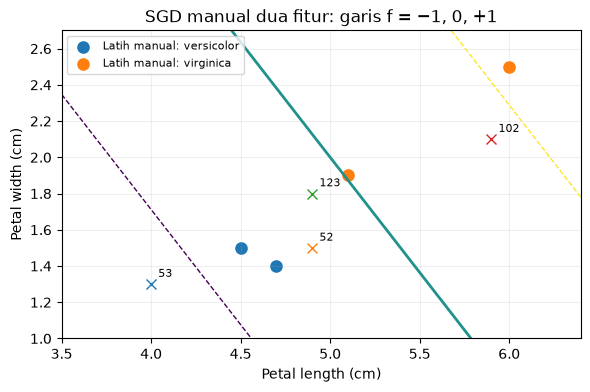

In [7]:
svm_queries=raw.loc[SVM_Q_IDS,PETAL+['kelas']].copy()
svm_queries['x1']=svm_queries['petal_length']-5
svm_queries['x2']=svm_queries['petal_width']-2
svm_queries['f_1_fitur']=w_1d[0]*svm_queries['x1']+b_1d
svm_queries['f_2_fitur']=w_2d[0]*svm_queries['x1']+w_2d[1]*svm_queries['x2']+b_2d
svm_queries['pred_1_fitur']=np.where(svm_queries['f_1_fitur']>0,'virginica','versicolor')
svm_queries['pred_2_fitur']=np.where(svm_queries['f_2_fitur']>0,'virginica','versicolor')
svm_queries['benar_2_fitur']=svm_queries['pred_2_fitur']==svm_queries['kelas']
print('Prediksi Q1–Q4 (Q1=53,Q2=52,Q3=123,Q4=102):')
display(svm_queries.round(5))
# Garis f=-1,0,+1 dari hasil 5 update; tidak sama dengan fit SVC.
xx=np.linspace(3.5,6.4,160);yy=np.linspace(1.0,2.7,160)
XX,YY=np.meshgrid(xx,yy)
Z=w_2d[0]*(XX-5)+w_2d[1]*(YY-2)+b_2d
fig,ax=plt.subplots(figsize=(6.7,4.0))
for k in ['versicolor','virginica']:
    d=raw.loc[[51,100,50,101]].query('kelas==@k')
    ax.scatter(d['petal_length'],d['petal_width'],s=65,label='Latih manual: '+k)
for sid,r in svm_queries.iterrows():
    ax.plot(r.petal_length,r.petal_width,marker='x',markersize=7)
    ax.annotate(str(sid),(r.petal_length+.04,r.petal_width+.04),fontsize=8)
ax.contour(XX,YY,Z,levels=[-1,0,1],linestyles=['--','-','--'],linewidths=[1,2,1])
ax.set(xlabel='Petal length (cm)',ylabel='Petal width (cm)',title='SGD manual dua fitur: garis f = −1, 0, +1')
ax.legend(fontsize=8);ax.grid(alpha=.2);plt.show()

**PERTANYAAN P11.4-2** — Hitung skor Q1–Q4 secara manual menggunakan model dua fitur iterasi 5. Berapa prediksi benar? Mengapa penambahan Petal Width dapat membantu, tetapi tidak menjamin Q3 benar?

**✍ JAWABAN MAHASISWA P11.4-2**

Model: f(x) = 0,815189·x₁ + 0,641220·x₂ + 0; prediksi Virginica jika f > 0.

| Q | ID | x₁ | x₂ | Skor f | Prediksi | Asli | Benar? |
|---|---|---|---|---|---|---|---|
| Q1 | 53 | −1,0 | −0,7 | −0,815189 − 0,448854 = **−1,26404** | V | V | ✔ |
| Q2 | 52 | −0,1 | −0,5 | −0,081519 − 0,320610 = **−0,40213** | V | V | ✔ |
| Q3 | 123 | −0,1 | −0,2 | −0,081519 − 0,128244 = **−0,20976** | V | G | ✘ |
| Q4 | 102 | 0,9 | 0,1 | 0,733670 + 0,064122 = **0,79779** | G | G | ✔ |

**Prediksi benar: 3 dari 4.**

Petal width membantu karena Virginica umumnya punya kelopak lebih lebar. Contohnya Q2 (ID 52) salah pada model satu fitur (f = 0,368 → G) tapi benar pada model dua fitur karena x₂ = −0,5 menarik skornya ke negatif. Namun Q3 tetap salah: panjangnya 4,9 (sama dengan Q2) dan lebarnya 1,8, yang masih di bawah titik acuan 2,0, sehingga kedua suku bernilai negatif. Bobot yang dipakai juga hasil dari **hanya 5 update SGD pada 4 bunga**, jadi garis f = 0 belum optimal dan jatuh tepat di daerah overlap Versicolor–Virginica. Menambah fitur memberi informasi tambahan, tetapi tidak menjamin titik yang berada dekat batas atau di daerah overlap pasti terklasifikasi benar.

## P11.5 — EDA hanya pada training

Gunakan **data train saja** untuk membaca distribusi, skala dan korelasi dua fitur. Jika ingin menghitung parameter preprocessing (mean dan simpangan baku scaler), `StandardScaler` harus di-`fit` hanya pada **training**, idealnya di dalam `Pipeline`.

Catatan: GaussianNB tidak menuntut distribusi **gabungan semua kelas** berbentuk Gaussian. Asumsinya adalah distribusi **tiap fitur bersyarat pada kelas**, dan independensi kondisional antar fitur. SVM tidak mensyaratkan data Gaussian.

Missing hanya training:


,jumlah_missing
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0


Ringkasan fitur training:


,petal_length,petal_width
count,90.000,90.000
mean,3.736,1.206
std,1.739,0.763
min,1.000,0.100
25%,1.525,0.300
50%,4.200,1.300
75%,5.075,1.800
max,6.900,2.500


Kelas training:


,jumlah
kelas,
versicolor,31
virginica,30
setosa,29


Korelasi panjang & lebar petal dalam training:
0.9595


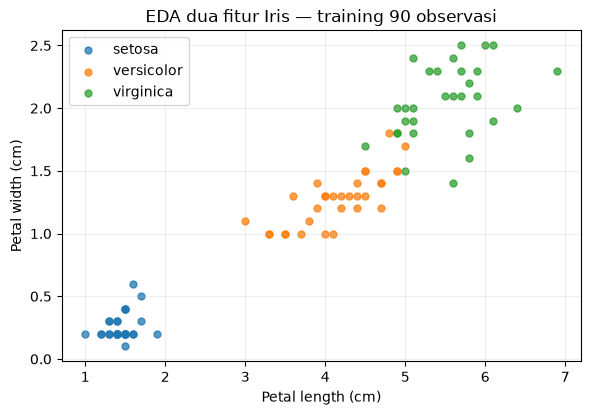

Korelasi bersyarat pada kelas (training):
setosa 0.2788
versicolor 0.7708
virginica 0.3989


In [8]:
train_view=X_tr.copy()
train_view['kelas']=[iris.target_names[i] for i in y_train]
print('Missing hanya training:');display(X_train.isna().sum().to_frame('jumlah_missing'))
print('Ringkasan fitur training:');display(X_tr.describe().round(3))
print('Kelas training:');display(train_view['kelas'].value_counts().to_frame('jumlah'))
print('Korelasi panjang & lebar petal dalam training:')
print(round(float(X_tr.corr().iloc[0,1]),4))
fig,ax=plt.subplots(figsize=(6.7,4.3))
for k,group in train_view.groupby('kelas'):
    ax.scatter(group['petal_length'],group['petal_width'],alpha=.75,s=25,label=k)
ax.set(xlabel='Petal length (cm)',ylabel='Petal width (cm)',title='EDA dua fitur Iris — training 90 observasi')
ax.legend();ax.grid(alpha=.2);plt.show()
print('Korelasi bersyarat pada kelas (training):')
for k,group in train_view.groupby('kelas'):
    print(k,round(float(group[PETAL].corr().iloc[0,1]),4))

**PERTANYAAN P11.5-1** — Tuliskan tiga temuan EDA yang relevan untuk GaussianNB dan SVM: sebaran kelas, overlap Versicolor–Virginica, serta korelasi dua fitur. Mengapa histogram gabungan tidak cukup untuk menilai asumsi GaussianNB?

**✍ JAWABAN MAHASISWA P11.5-1**

1. **Sebaran kelas seimbang:** training berisi setosa 29, versicolor 31, virginica 30, tanpa missing value. Prior GaussianNB jadi hampir rata (~1/3), dan SVM tidak perlu `class_weight='balanced'`. Macro-F1 tetap dipakai supaya ketiga kelas dinilai setara.
2. **Overlap Versicolor–Virginica:** setosa terpisah jelas (length 1,0–1,9; width 0,1–0,6). Versicolor (length 3,0–5,0; width 1,0–1,8) dan Virginica (length 4,5–6,9; width 1,4–2,5) bertumpuk di daerah **length 4,5–5,0 dan width 1,4–1,8**. Hampir semua kesalahan dari kedua model akan muncul di daerah ini, dan di sinilah bentuk batas SVM (`C`, `gamma`) maupun varians GaussianNB paling berpengaruh.
3. **Korelasi fitur:** korelasi length–width gabungan = **0,9595**, tetapi per kelas jauh lebih kecil: setosa 0,2788, versicolor 0,7708, virginica 0,3989. Korelasi gabungan yang tinggi terutama muncul karena perbedaan antar kelas. Yang relevan untuk asumsi independensi GaussianNB adalah korelasi **dalam kelas**, dan pada versicolor (0,77) asumsi itu jelas dilanggar. Bagi SVM korelasi ini tidak menjadi syarat, tetapi skala fitur tetap disamakan dengan `StandardScaler`.

Histogram gabungan tidak cukup karena GaussianNB tidak mengasumsikan data keseluruhan berdistribusi normal. Yang diasumsikan adalah **setiap fitur bersyarat pada kelas** berdistribusi Gaussian, ditambah independensi antar fitur dalam kelas. Histogram gabungan Iris justru bimodal/multimodal (setosa terpisah jauh), padahal distribusi per kelasnya bisa saja mendekati normal. Jadi pengecekan harus dilakukan per kelas–per fitur.

## P11.6 — Training dan perbandingan GaussianNB vs kernel SVM

Semua model menggunakan **dua fitur Petal** dan split yang **sama**. `GaussianNB` tidak membutuhkan scaler untuk bekerja; `SVC` dan KNN biasanya sensitif terhadap skala fitur sehingga kita memakai `Pipeline([('scale',StandardScaler()), ('model',SVC(...))])`.

### Fungsi parameter `SVC` dan komponen preprocessing

| Parameter / API | Fungsi | Catatan |
|---|---|---|
| `kernel='linear'` | Batas linear pada ruang fitur | `gamma`, `degree`, `coef0` tidak memengaruhi kernel ini |
| `kernel='rbf'` | Batas nonlinier berdasarkan jarak $e^{-\gamma\|x-z\|^2}$ | `gamma` mengontrol kelokalan pengaruh |
| `kernel='poly'` | Interaksi polinomial $(\gamma x^\top z+\text{coef0})^{\text{degree}}$ | `degree`, `gamma`, `coef0` berperan |
| `C` | Mengatur kompromi regularisasi dan penalti pelanggaran margin | Lebih besar berarti penalti pelanggaran relatif lebih besar |
| `gamma='scale'` | $1/(n_{fitur}\cdot Var(X_{masuk\ SVC}))$ | Dihitung dari **data yang sudah di-scale** saat ada Pipeline |
| `gamma='auto'` | $1/n_{fitur}$ | Berbeda dengan `scale` jika varians total bukan 1 |
| `degree` / `coef0` | Derajat dan konstanta kernel polynomial | Tidak dipakai oleh kernel linear |
| `class_weight` | Mengatur bobot penalti per kelas | Coba `balanced` jika ketidakseimbangan signifikan |
| `tol` / `max_iter` | Toleransi dan batas iterasi solver libsvm | **Bukan** epoch SGD manual |
| `shrinking` / `cache_size` | Pengaturan optimasi dan memori kernel | Tidak mengubah definisi kelas |
| `probability` | Mengaktifkan estimasi probabilitas SVC dengan komputasi tambahan pada versi yang mendukung | Di praktikum ini **tidak digunakan**; `decision_function` bukan probabilitas |
| `decision_function_shape` / `break_ties` | Bentuk skor dan penanganan seri untuk multikelas | Pelatihan SVC tetap berbasis pasangan kelas (`ovo`) |
| `random_state` | Mengontrol komponen acak yang relevan, misalnya probabilitas SVC | Jangan menyamakan dengan `random_state` split |
| `StandardScaler()` | Belajar mean dan standar deviasi di training | `.fit_transform` dikerjakan oleh Pipeline saat `.fit()` |
| `Pipeline([('scale',...),('model',...)])` | Mencegah data leakage dan membundel preprocessing+model | Pemanggilan `.predict` otomatis memakai scaler yang sudah dilatih |
| `fit`, `predict`, `decision_function` | Latih, prediksi label, dan skor keputusan | Skor SVC multikelas bukan probabilitas posterior GaussianNB |
| `n_support_`, `support_vectors_`, `coef_` | Jumlah/posisi support vectors dan bobot linear bila tersedia | `coef_` hanya untuk kernel linear; SV ada di ruang fitur setelah scaling |

Dokumentasi resmi: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

PERBANDINGAN VALIDATION:


,model,macro_f1_train,macro_f1_val,accuracy_val,n_support
0,GaussianNB,0.9563,1.0,1.0,NaN
1,KNN k5,0.9563,1.0,1.0,NaN
2,Logistic Regression,0.9453,1.0,1.0,NaN
3,SVM Linear,0.9563,1.0,1.0,22.0
4,SVM Polynomial d2,0.9563,1.0,1.0,18.0
5,SVM RBF,0.9563,1.0,1.0,28.0


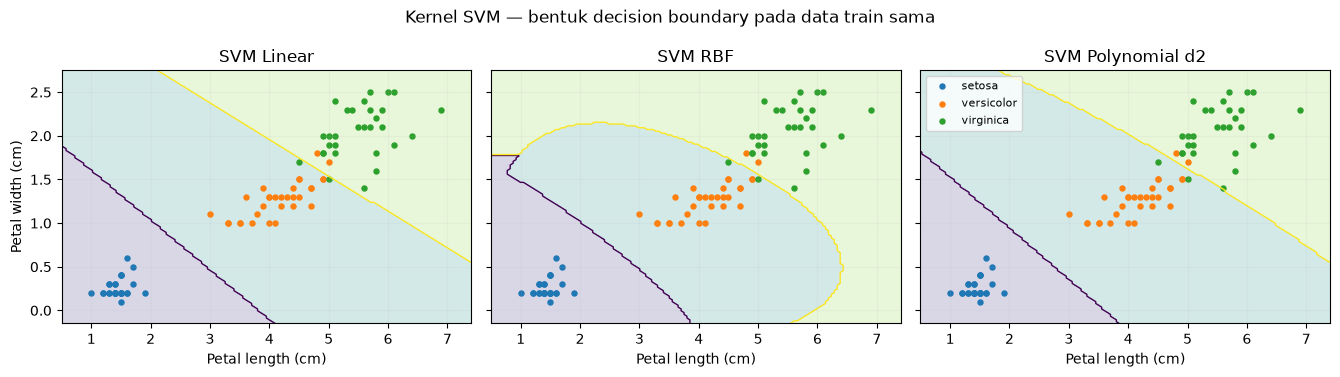

In [9]:
models={
 'GaussianNB':GaussianNB(var_smoothing=1e-9),
 'SVM Linear':Pipeline([('scale',StandardScaler()),('model',SVC(kernel='linear',C=1.0))]),
 'SVM RBF':Pipeline([('scale',StandardScaler()),('model',SVC(kernel='rbf',C=1.0,gamma='scale'))]),
 'SVM Polynomial d2':Pipeline([('scale',StandardScaler()),('model',SVC(kernel='poly',C=1.0,degree=2,gamma='scale',coef0=1.0))]),
 'KNN k5':Pipeline([('scale',StandardScaler()),('model',KNeighborsClassifier(n_neighbors=5))]),
 'Logistic Regression':Pipeline([('scale',StandardScaler()),('model',LogisticRegression(max_iter=1500,random_state=SEED))])
}
rows=[]
for name,model in models.items():
    model.fit(X_tr,y_train)
    train_pred=model.predict(X_tr)
    val_pred=model.predict(X_va)
    rows.append({'model':name,'macro_f1_train':f1_score(y_train,train_pred,average='macro'),
                 'macro_f1_val':f1_score(y_val,val_pred,average='macro'),
                 'accuracy_val':accuracy_score(y_val,val_pred),
                 'n_support':int(model.named_steps['model'].n_support_.sum()) if name.startswith('SVM') else np.nan})
comparison=pd.DataFrame(rows).sort_values(['macro_f1_val','model'],ascending=[False,True]).reset_index(drop=True)
print('PERBANDINGAN VALIDATION:')
display(comparison.round(4))

# Grafik tiap kernel pada split yang sama; overlay titik TRAIN saja
fig,axes=plt.subplots(1,3,figsize=(13.5,3.8),sharex=True,sharey=True)
xx=np.linspace(X_tr['petal_length'].min()-.5,X_tr['petal_length'].max()+.5,140)
yy=np.linspace(X_tr['petal_width'].min()-.25,X_tr['petal_width'].max()+.25,140)
GX,GY=np.meshgrid(xx,yy)
mesh=pd.DataFrame({'petal_length':GX.ravel(),'petal_width':GY.ravel()})
for a,name in zip(axes,['SVM Linear','SVM RBF','SVM Polynomial d2']):
    Z=models[name].predict(mesh).reshape(GX.shape)
    a.contourf(GX,GY,Z,levels=[-.5,.5,1.5,2.5],alpha=.2)
    a.contour(GX,GY,Z,levels=[.5,1.5],linewidths=1)
    for ynum,k in enumerate(iris.target_names):
        pts=X_tr[y_train==ynum]
        a.scatter(pts['petal_length'],pts['petal_width'],s=13,label=k)
    a.set(title=name,xlabel='Petal length (cm)');a.grid(alpha=.1)
axes[0].set_ylabel('Petal width (cm)');axes[-1].legend(fontsize=8)
fig.suptitle('Kernel SVM — bentuk decision boundary pada data train sama')
plt.tight_layout();plt.show()

**PERTANYAAN P11.6-1** — Gunakan tabel dan grafik untuk membandingkan GaussianNB, SVM Linear, RBF, Polynomial, KNN, dan Logistic Regression. Apakah model dengan grafik batas paling rumit pasti paling baik pada validation?

**✍ JAWABAN MAHASISWA P11.6-1**

Hasil validation (30 data, fitur petal):
| Model | Macro-F1 train | Macro-F1 val | Accuracy val | n_support |
|---|---|---|---|---|
| GaussianNB | 0,9563 | 1,0000 | 1,0000 | – |
| KNN k5 | 0,9563 | 1,0000 | 1,0000 | – |
| Logistic Regression | 0,9453 | 1,0000 | 1,0000 | – |
| SVM Linear | 0,9563 | 1,0000 | 1,0000 | 22 |
| SVM Polynomial d2 | 0,9563 | 1,0000 | 1,0000 | 18 |
| SVM RBF | 0,9563 | 1,0000 | 1,0000 | 28 |

Keenam model **seri sempurna** di validation (Macro-F1 = Accuracy = 1,0). Di training, hampir semuanya 0,9563 (Logistic Regression sedikit lebih rendah, 0,9453), artinya beberapa titik training di daerah overlap tetap salah. Grafik menunjukkan batas linear berupa garis lurus, sedangkan RBF dan polynomial sedikit melengkung, terutama di sekitar overlap Versicolor–Virginica. Meski bentuknya berbeda, keputusannya pada 30 data validation sama persis.

Jadi **tidak**: model dengan batas paling rumit tidak otomatis paling bagus. Batas yang rumit memang bisa mengikuti training lebih rapat, tetapi itu berisiko overfitting. Di sini model linear yang sederhana sudah mencapai skor yang sama. Karena validation hanya 30 baris dan semua model seri, perbedaannya tidak bisa disimpulkan dari angka ini. Kalau skornya sama, model yang lebih sederhana/stabil lebih masuk akal dipilih, atau perlu evaluasi tambahan (misalnya cross-validation).

## P11.7 — Eksperimen parameter yang terkontrol

**Eksperimen A: GaussianNB** — ubah hanya `var_smoothing` sambil menjaga train/validation dan fitur sama. `priors` bisa diganti secara terpisah untuk demonstrasi, tetapi jangan menebak prior tanpa alasan (misalnya prevalensi lapangan).

**Eksperimen B: SVM RBF** — ubah `C` dan `gamma` pada split yang sama. `gamma` kecil biasanya membuat pengaruh kernel lebih luas, sedangkan `gamma` besar lebih lokal; keduanya tetap perlu diuji bersama `C`. Setelah itu uji contoh Polynomial `degree` dan `coef0`. **Jangan menyentuh test saat tuning.**

In [10]:
nb_tune_rows=[]
for vsm in [1e-9,1e-4,1e-2,1e-1]:
    model=GaussianNB(var_smoothing=vsm).fit(X_tr,y_train)
    nb_tune_rows.append({'var_smoothing':vsm,'epsilon_':model.epsilon_,
      'macro_f1_train':f1_score(y_train,model.predict(X_tr),average='macro'),
      'macro_f1_val':f1_score(y_val,model.predict(X_va),average='macro')})
nb_tuning=pd.DataFrame(nb_tune_rows).sort_values(['macro_f1_val','var_smoothing'],ascending=[False,True]).reset_index(drop=True)
print('GaussianNB: pengaruh var_smoothing (test belum dibuka)')
display(nb_tuning.round(6))
nb_prior_demo=GaussianNB(priors=[.2,.5,.3],var_smoothing=1e-9).fit(X_tr,y_train)
print('Prior belajar dari training:',np.round(nb_baseline.class_prior_,4))
print('Prior pengguna [0.2,0.5,0.3]:',np.round(nb_prior_demo.class_prior_,4))
print('Parameter prior tidak boleh dipilih dari test.')

GaussianNB: pengaruh var_smoothing (test belum dibuka)


,var_smoothing,epsilon_,macro_f1_train,macro_f1_val
0,0.0000,0.000000,0.956272,1.0
1,0.0001,0.000299,0.956272,1.0
2,0.0100,0.029892,0.956272,1.0
3,0.1000,0.298918,0.956272,1.0


Prior belajar dari training: [0.3222 0.3444 0.3333]
Prior pengguna [0.2,0.5,0.3]: [0.2 0.5 0.3]
Parameter prior tidak boleh dipilih dari test.


SVM RBF: pengaruh C × gamma

,C,gamma,macro_f1_train,macro_f1_val,jumlah_support
0,0.1,0.50,0.9453,1.0000,77
1,0.1,5.00,0.9672,1.0000,71
2,1.0,0.05,0.9453,1.0000,56
3,1.0,0.50,0.9563,1.0000,28
4,1.0,5.00,0.9672,1.0000,31
5,10.0,0.05,0.9563,1.0000,22
6,10.0,0.50,0.9563,1.0000,19
7,10.0,5.00,0.9672,1.0000,28
8,0.1,0.05,0.5580,0.5476,90


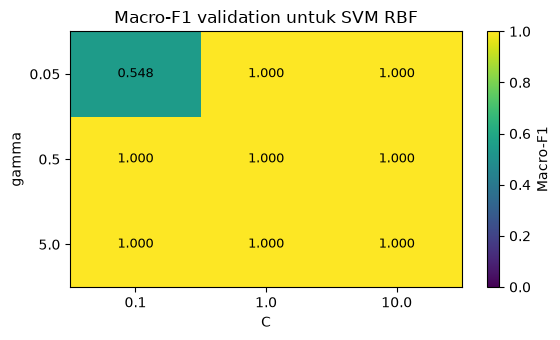

SVM Polynomial — degree × coef0:


,degree,coef0,macro_f1_val
0,2,0.0,0.9012
1,2,1.0,1.0000
2,3,0.0,0.9649
3,3,1.0,1.0000


Linear mengabaikan gamma: True


In [11]:
svm_tune_rows=[]
for C_value in [.1,1.,10.]:
    for gamma_value in [.05,.5,5.]:
        model=Pipeline([('scale',StandardScaler()),
                        ('model',SVC(kernel='rbf',C=C_value,gamma=gamma_value))])
        model.fit(X_tr,y_train)
        svm_tune_rows.append({'C':C_value,'gamma':gamma_value,
          'macro_f1_train':f1_score(y_train,model.predict(X_tr),average='macro'),
          'macro_f1_val':f1_score(y_val,model.predict(X_va),average='macro'),
          'jumlah_support':int(model.named_steps['model'].n_support_.sum())})
svm_tuning=pd.DataFrame(svm_tune_rows).sort_values(['macro_f1_val','C','gamma'],ascending=[False,True,True]).reset_index(drop=True)
print('SVM RBF: pengaruh C × gamma')
display(svm_tuning.round(4))
heat=svm_tuning.pivot(index='gamma',columns='C',values='macro_f1_val').sort_index()
fig,ax=plt.subplots(figsize=(5.8,3.5));im=ax.imshow(heat.values,aspect='auto',vmin=0,vmax=1)
ax.set_xticks(range(len(heat.columns)),[str(t) for t in heat.columns])
ax.set_yticks(range(len(heat.index)),[str(t) for t in heat.index])
ax.set(xlabel='C',ylabel='gamma',title='Macro-F1 validation untuk SVM RBF')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]): ax.text(j,i,f'{heat.iloc[i,j]:.3f}',ha='center',va='center',fontsize=9)
fig.colorbar(im,ax=ax,label='Macro-F1');plt.tight_layout();plt.show()

poly_rows=[]
for degree in [2,3]:
    for coef0 in [0.,1.]:
        model=Pipeline([('scale',StandardScaler()),('model',SVC(kernel='poly',degree=degree,coef0=coef0,gamma='scale',C=1.))]).fit(X_tr,y_train)
        poly_rows.append({'degree':degree,'coef0':coef0,
              'macro_f1_val':f1_score(y_val,model.predict(X_va),average='macro')})
print('SVM Polynomial — degree × coef0:')
display(pd.DataFrame(poly_rows).round(4))
lin1=Pipeline([('scale',StandardScaler()),('model',SVC(kernel='linear',gamma=.05))]).fit(X_tr,y_train)
lin2=Pipeline([('scale',StandardScaler()),('model',SVC(kernel='linear',gamma=5.))]).fit(X_tr,y_train)
print('Linear mengabaikan gamma:',np.array_equal(lin1.predict(X_va),lin2.predict(X_va)))
assert np.array_equal(lin1.predict(X_va),lin2.predict(X_va))

**PERTANYAAN P11.7-1** — Parameter mana yang merupakan smoothing **relatif** GaussianNB, parameter mana yang mengatur kompromi penalti SVM, dan parameter mana yang mengatur kelokalan RBF? Pilih masing-masing kandidat berdasarkan validation, bukan test.

**✍ JAWABAN MAHASISWA P11.7-1**

- **Smoothing relatif GaussianNB:** `var_smoothing`. Nilainya dikalikan varians fitur terbesar di training: ε = var_smoothing × max Var. Contoh output: 1e-2 → ε = 0,029892; 1e-1 → ε = 0,298918.
- **Kompromi penalti SVM:** `C`. Nilai C kecil memberi margin lebar dan lebih toleran pada pelanggaran margin (support vector banyak). C besar menghukum pelanggaran lebih keras. Contoh: γ = 0,5 → C = 0,1: 77 SV; C = 1: 28 SV; C = 10: 19 SV.
- **Kelokalan RBF:** `gamma`. γ kecil membuat pengaruh tiap titik meluas sehingga batas lebih halus, sedangkan γ besar membuat pengaruhnya lokal sehingga batas lebih berliku.

**Pemilihan berdasarkan validation:**
- GaussianNB: keempat nilai `var_smoothing` (1e-9 s.d. 1e-1) sama-sama Macro-F1 val = 1,0. Dengan aturan tie-break yang ditetapkan sebelumnya (nilai terkecil), dipilih **var_smoothing = 1e-9** (default).
- SVM RBF: delapan dari sembilan kombinasi memberi Macro-F1 val = 1,0. Hanya **C = 0,1 & γ = 0,05** yang gagal (val 0,5476, train 0,5580, 90 SV, jadi model terlalu underfit). Tie-break (C terkecil lalu γ terkecil) memilih **C = 0,1, γ = 0,5**.

Catatan jujur: karena banyak kombinasi seri, validation 30 data sebenarnya tidak cukup untuk membedakannya. Konfigurasi terpilih (C = 0,1, γ = 0,5) bahkan punya train F1 lebih rendah (0,9453) dan 77 SV. Pemilihan tetap tidak memakai test sama sekali.

**PERTANYAAN P11.7-2** — Mengapa `gamma` tidak mengubah hasil kernel linear? Apa fungsi `degree` dan `coef0` pada Polynomial? Jika train F1 jauh lebih tinggi daripada validation F1, apa indikasinya?

**✍ JAWABAN MAHASISWA P11.7-2**

- **Gamma vs kernel linear:** kernel linear hanya menghitung $K(x,z)=x^\top z$, tanpa parameter `gamma`. Nilai `gamma` diterima oleh `SVC` tetapi tidak dipakai, sehingga prediksi γ = 0,05 dan γ = 5 identik (output: `Linear mengabaikan gamma: True`).
- **degree dan coef0 pada Polynomial:** kernelnya $K(x,z)=(\gamma x^\top z+\text{coef0})^{\text{degree}}$. `degree` menentukan orde polinomial (makin besar, batas makin lentur/kompleks). `coef0` menentukan bobot suku berorde rendah: dengan coef0 = 0 hanya suku orde tertinggi yang tersisa, sedangkan coef0 > 0 juga memasukkan suku orde lebih rendah, termasuk suku linear. Bukti di output: degree 2, coef0 = 0 → Macro-F1 val 0,9012; degree 2, coef0 = 1 → 1,0000; degree 3, coef0 = 0 → 0,9649; degree 3, coef0 = 1 → 1,0000. Untuk degree 2 tanpa coef0, kernel hanya berisi suku kuadrat murni (tidak ada suku linear), sehingga batas sederhana yang dibutuhkan susah dibentuk.
- **Train F1 ≫ validation F1** menandakan **overfitting**: model terlalu menghafal training (misalnya γ terlalu besar atau C terlalu besar) sehingga gagal generalisasi. Sebaliknya, kalau train dan val sama-sama rendah (seperti C = 0,1, γ = 0,05: 0,558 / 0,548), itu tanda **underfitting**. Di eksperimen ini selisih train–val kecil, dan val malah lebih tinggi karena validation kebetulan tidak memuat banyak titik overlap.

## P11.8 — Kunci final dan evaluasi test **satu kali**

Sebelum membaca hasil test, kita mengambil **dua model final yang telah ditentukan oleh validation**, yakni satu GaussianNB dan satu SVM RBF. Kedua model dilatih ulang pada **gabungan train+validation** untuk memakai seluruh informasi pelatihan yang diizinkan; test berjumlah 30 baris tetap tak terlihat sampai sel ini. Ini adalah **evaluasi dua kandidat pra-terdaftar**, bukan pemilihan ulang hyperparameter berdasarkan test.

**Penting:** GaussianNB `predict_proba` menghasilkan posterior; SVC `decision_function` menghasilkan skor. Jangan membandingkannya sebagai angka yang sejenis.

In [12]:
# Pemilihan di atas berdasarkan VALIDATION saja (tie-break ditentukan sebelumnya)
NB_FINAL_SMOOTH=float(nb_tuning.iloc[0]['var_smoothing'])
SVM_FINAL_C=float(svm_tuning.iloc[0]['C'])
SVM_FINAL_GAMMA=float(svm_tuning.iloc[0]['gamma'])
FINAL_FEATURES=PETAL.copy()
print('Konfigurasi yang DIKUNCI sebelum test:')
print('GaussianNB:',NB_FINAL_SMOOTH)
print('SVM RBF: C=',SVM_FINAL_C,'gamma=',SVM_FINAL_GAMMA)
X_train_val=pd.concat([X_tr,X_va],axis=0)
y_train_val=pd.concat([y_train,y_val],axis=0)
final_nb=GaussianNB(var_smoothing=NB_FINAL_SMOOTH).fit(X_train_val,y_train_val)
final_svm=Pipeline([('scale',StandardScaler()),
                    ('model',SVC(kernel='rbf',C=SVM_FINAL_C,gamma=SVM_FINAL_GAMMA))]).fit(X_train_val,y_train_val)
# Berikut ini satu-satunya sel yang menggunakan test untuk mengevaluasi model
X_te=X_test[FINAL_FEATURES]
final_scores=[]
for name,model in [('GaussianNB',final_nb),('SVM RBF',final_svm)]:
    pred=model.predict(X_te)
    cm=confusion_matrix(y_test,pred,labels=[0,1,2])
    final_scores.append({'model':name,'macro_f1_test':f1_score(y_test,pred,average='macro'),
                          'accuracy_test':accuracy_score(y_test,pred)})
    print('\nTEST',name,'| Confusion Matrix:')
    display(pd.DataFrame(cm,index=['akt_S','akt_V','akt_G'],columns=['pred_S','pred_V','pred_G']))
    print('Recall tiap kelas:',np.round(recall_score(y_test,pred,labels=[0,1,2],average=None),4))
final_summary=pd.DataFrame(final_scores)
print('Rekap TEST — hanya untuk pelaporan, bukan tuning:')
display(final_summary.round(4))

# Inferensi 2 bunga hipotetik (tidak punya ground truth; jangan dihitung sebagai akurasi)
X_new=pd.DataFrame({'petal_length':[4.8,6.1],'petal_width':[1.4,2.3]})
new_nb=final_nb.predict(X_new);new_svm=final_svm.predict(X_new)
print('Prediksi data pengukuran baru tanpa label sebenarnya:')
display(X_new.assign(GaussianNB=[iris.target_names[i] for i in new_nb],
                     SVM_RBF=[iris.target_names[i] for i in new_svm]))

Konfigurasi yang DIKUNCI sebelum test:
GaussianNB: 1e-09
SVM RBF: C= 0.1 gamma= 0.5

TEST GaussianNB | Confusion Matrix:


,pred_S,pred_V,pred_G
akt_S,10,0,0
akt_V,0,9,1
akt_G,0,1,9


Recall tiap kelas: [1.  0.9 0.9]

TEST SVM RBF | Confusion Matrix:


,pred_S,pred_V,pred_G
akt_S,10,0,0
akt_V,0,10,0
akt_G,0,1,9


Recall tiap kelas: [1.  1.  0.9]
Rekap TEST — hanya untuk pelaporan, bukan tuning:


,model,macro_f1_test,accuracy_test
0,GaussianNB,0.9333,0.9333
1,SVM RBF,0.9666,0.9667


Prediksi data pengukuran baru tanpa label sebenarnya:


,petal_length,petal_width,GaussianNB,SVM_RBF
0,4.8,1.4,versicolor,versicolor
1,6.1,2.3,virginica,virginica


**PERTANYAAN P11.8-1** — Laporkan Macro-F1 test, Accuracy test, confusion matrix, dan contoh satu kelas yang sering tertukar. Bandingkan GaussianNB dan SVM tanpa mengubah parameter setelah test.

**✍ JAWABAN MAHASISWA P11.8-1**

Konfigurasi dikunci sebelum test: GaussianNB `var_smoothing = 1e-9`; SVM RBF `C = 0,1`, `gamma = 0,5`. Keduanya dilatih ulang pada train + val (120 baris), lalu dievaluasi satu kali pada test (30 baris, 10 per kelas).

| Model | Macro-F1 test | Accuracy test | Recall (S, V, G) |
|---|---|---|---|
| GaussianNB | **0,9333** | **0,9333** (28/30) | 1,0; 0,9; 0,9 |
| SVM RBF | **0,9666** | **0,9667** (29/30) | 1,0; 1,0; 0,9 |

Confusion matrix GaussianNB (baris = aktual S/V/G, kolom = prediksi S/V/G): [[10, 0, 0], [0, 9, **1**], [0, **1**, 9]].
Confusion matrix SVM RBF: [[10, 0, 0], [0, 10, 0], [0, **1**, 9]].

**Kelas yang tertukar:** selalu antara Versicolor dan Virginica, sedangkan setosa 100% benar di kedua model. Contohnya ID 133 (5,1; 1,5) yang aslinya **Virginica** diprediksi Versicolor oleh kedua model. GaussianNB juga salah pada ID 83 (5,1; 1,6) yang aslinya Versicolor tapi diprediksi Virginica. Kedua titik ini persis berada di daerah overlap yang ditemukan saat EDA (length 4,5–5,0+, width 1,4–1,8).

**Perbandingan:** SVM RBF unggul tipis, hanya selisih **satu bunga** (29 vs 28 benar). Dengan test sebanyak 30 baris, selisih 1 data = 3,3 poin, sehingga perbedaan ini tidak bisa dianggap signifikan. Parameter tidak diubah sama sekali setelah melihat hasil test. Prediksi dua bunga hipotetik [4,8; 1,4] → versicolor dan [6,1; 2,3] → virginica (sama di kedua model) tidak dihitung sebagai akurasi karena tidak punya label asli.

## P11.9 — Analisis akhir, portofolio, dan pengumpulan

Tuliskan kesimpulan **120–170 kata**, memuat: (1) kesesuaian manual–Python untuk Naive Bayes; (2) hasil bobot SGD SVM; (3) tiga perbedaan pendekatan NB/SVM; (4) parameter yang paling berpengaruh; (5) bukti validation vs test; (6) satu keterbatasan dan satu usulan eksperimen lanjut.

**Berkas yang dikumpulkan:** `P11_NIM_Nama_NaiveBayes_SVM.ipynb` — seluruh jawaban P11.1–P11.9, semua sel kode berhasil dijalankan, tabel dan grafik terlihat. Jangan kirim kunci dosen.

**PERTANYAAN P11.9-1** — Tulis kesimpulan 120–170 kata berdasarkan hasil yang Anda peroleh. Mengapa menyatakan “SVM selalu lebih baik daripada GaussianNB” tidak dapat dibenarkan dari satu dataset dan satu split?

**✍ JAWABAN MAHASISWA P11.9-1**

**Kesimpulan:** Perhitungan manual GaussianNB sama persis dengan scikit-learn: prior 0,5, mean, varians ddof = 0, dan posterior ID 53 = 0,999339, asalkan `var_smoothing` dikonversi menjadi 0,152413 agar `epsilon_` = 0,05. Lima update SGD SVM dua fitur menghasilkan w = (0,8152; 0,6412), b = 0, dan memprediksi benar 3 dari 4 kueri. Perbedaan pendekatannya: NB bersifat generatif probabilistik dengan asumsi independensi dan menghasilkan posterior; SVM bersifat diskriminatif, memaksimalkan margin dengan hinge loss, dan menghasilkan skor keputusan; NB tidak butuh scaling, sedangkan SVM butuh. Parameter yang paling berpengaruh adalah C dan gamma, karena kombinasi C = 0,1 dan gamma = 0,05 menjatuhkan Macro-F1 validation ke 0,548. Hampir semua model seri 1,0 di validation, sedangkan di test SVM RBF mendapat 0,967 dan GaussianNB 0,933. Keterbatasannya, validation dan test hanya 30 baris. Usulan lanjutan: memakai StratifiedKFold berulang pada train+validation dengan keempat fitur.

**Mengapa "SVM selalu lebih baik" tidak bisa dibenarkan:** selisihnya hanya satu bunga dari 30 data uji pada **satu** split acak (seed 2026) dan **satu** dataset kecil. Split lain bisa saja membalik hasilnya, dan di validation keduanya seri. Klaim "selalu" butuh bukti dari banyak dataset, banyak split atau cross-validation, dan uji signifikansi. Itu pun hanya berlaku pada kondisi yang diuji (no free lunch).

---
### Pengayaan opsional
1. Gunakan **empat fitur Iris** pada split yang sama, tanpa melakukan split ulang; bandingkan GaussianNB dan SVM. Catat apakah korelasi antar fitur makin tinggi.
2. Tampilkan histogram **per kelas-per fitur** dan boxplot; uji secara terbatas asumsi Gaussian dan independensi kondisional; jangan menganggap histogram gabungan sebagai syarat normalitas.
3. Bandingkan `GaussianNB(priors=[...])` dengan prior empiris **hanya bila memiliki dasar prevalensi**.
4. Uji `StratifiedKFold` pada train+validation (test tetap tertutup) dan dataset Wisconsin. Jangan gunakan hasil test untuk memilih hyperparameter.
5. Bandingkan waktu training tetapi catat spesifikasi mesin dan jumlah data; 150 Iris terlalu kecil untuk kesimpulan performa komputasi umum.

**Sumber resmi:**
- Iris: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
- GaussianNB: https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html
- SVC: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
- Pipeline: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- StandardScaler: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
